In [3]:
import pandas as pd
import yfinance as yf
# %matplotlib widget
# %matplotlib notebook
# %matplotlib widget

In [2]:
df_twtr = yf.download('AAPL', start='2026-11-01', end='2026-11-08', interval="30m")
df_twtr.columns = df_twtr.columns.droplevel(level=1)
df_twtr.index = df_twtr.index.map(lambda x: str(x)[:-6])
df_twtr.index = pd.to_datetime(df_twtr.index)
df_twtr.index
df_twtr

/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:559: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:505: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:509: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
[*********************100%***********************]  

Price,Close,High,Low,Open,Volume
Datetime,,,,,
2026-11-02 09:30:00,340.390015,343.779999,339.609985,342.670013,6774445
2026-11-02 10:00:00,340.329987,341.600006,339.660004,340.339996,3376692
2026-11-02 10:30:00,341.079987,342.320007,340.059998,340.329987,2319888
2026-11-02 11:00:00,341.190002,341.644989,340.119995,341.100006,1990212
2026-11-02 11:30:00,339.179993,341.264404,338.899994,341.204987,2927636
...,...,...,...,...,...
2026-11-06 13:30:00,344.709991,344.790009,344.010010,344.380005,1135355
2026-11-06 14:00:00,344.170013,344.869995,344.049988,344.765015,966608
2026-11-06 14:30:00,343.250488,344.479797,342.899994,344.149994,1216012


In [3]:
df_twtr.to_csv("AAPL.scv")

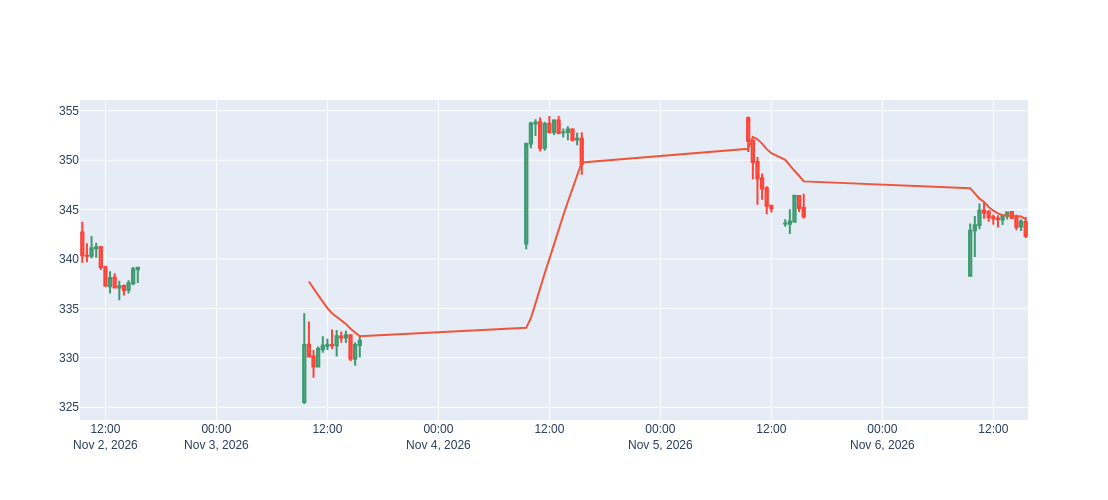

In [4]:
import plotly.graph_objects as go

import pandas as pd
from datetime import datetime



fig = go.Figure(data=[go.Candlestick(x=df_twtr.index,
                open=df_twtr['Open'],
                high=df_twtr['High'],
                low=df_twtr['Low'],
                close=df_twtr['Close'])
                     , go.Scatter(x=df_twtr.index, y = df_twtr["Close"].rolling(15).mean())])



fig.update_layout(xaxis_rangeslider_visible=False)

fig.update_layout(
    autosize=False,
    width=800,
    height=500,
    showlegend=False)
fig.show()

In [5]:
import mplfinance as mpf

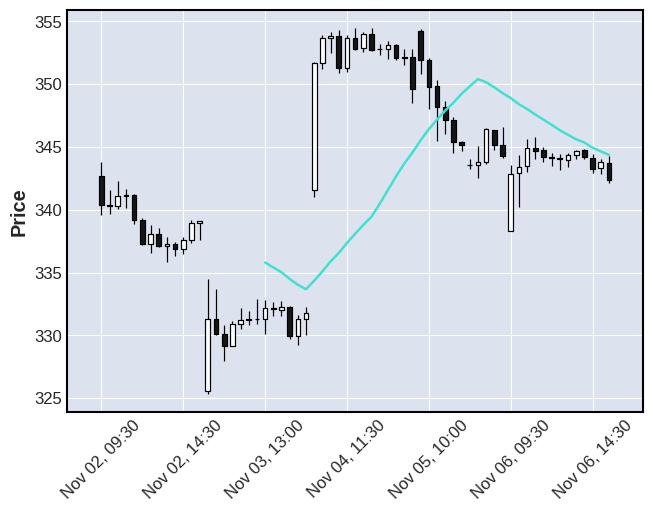

In [6]:
mpf.plot(df_twtr,
         type='candle',
         mav=21)

# Backtesting a strategy based on simple moving average

In [5]:
import backtrader as bt
import yfinance as yf
import pandas as pd
# Download data
data = yf.download('AAPL', start='2018-01-01', end='2024-01-01')
data.columns = data.columns.droplevel(level=1)
# Convert for Backtrader
datafeed = bt.feeds.PandasData(dataname=data)
# Define strategy


class SmaCross(bt.Strategy):
    def __init__(self):
        self.ma20 = bt.indicators.SimpleMovingAverage(self.data.close, period=20)
        # self.ma50 = bt.indicators.SimpleMovingAverage(self.data.close, period=50)
    def next(self):
        if not self.position:
            if self.data.close > self.ma20[0]:
                self.buy()
        elif self.data.close < self.ma20[0]:
            self.close()
# Set up Cerebro
cerebro = bt.Cerebro()
cerebro.addstrategy(SmaCross)
cerebro.adddata(datafeed)
cerebro.broker.set_cash(10_000)
cerebro.broker.setcommission(commission=0.002)
# Run backtest
print(f'Starting Portfolio Value: {cerebro.broker.getvalue():.2f}')
cerebro.run()
print(f'Final Portfolio Value: {cerebro.broker.getvalue():.2f}')

cerebro.plot(iplot=False, volume=False)

/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:559: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:576: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:578: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_index(inplace=T

Starting Portfolio Value: 10000.00
Final Portfolio Value: 10139.77


[[<Figure size 640x480 with 3 Axes>]]

In [1]:
from backtesting import Backtest, Strategy
from backtesting.lib import crossover

from backtesting.test import SMA, GOOG


class SmaCross(Strategy):
    def init(self):
        price = self.data.Close
        self.ma1 = self.I(SMA, price, 10)
        self.ma2 = self.I(SMA, price, 20)

    def next(self):
        if crossover(self.data.Close, self.ma2):
            self.buy()
        elif crossover(self.ma2, self.data.Close):
            self.sell()


bt = Backtest(GOOG, SmaCross, commission=.002,
              exclusive_orders=True)
stats = bt.run()
bt.plot()


/home/majidi/anaconda3/lib/python3.13/site-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (
/home/majidi/anaconda3/lib/python3.13/site-packages/backtesting/_plotting.py:55: UserWarning: Jupyter Notebook detected. Setting Bokeh output to notebook. This may not work in Jupyter clients without JavaScript support, such as old IDEs. Reset with `backtesting.set_bokeh_output(notebook=False)`.
  warnings.warn('Jupyter Notebook detected. '


Loading BokehJS ...

Backtest.run:   0%|          | 0/2128 [00:00<?, ?bar/s]

/tmp/ipykernel_5526/332384371.py:22: UserWarning: Some trades remain open at the end of backtest. Use `Backtest(..., finalize_trades=True)` to close them and include them in stats.
  stats = bt.run()


GridPlot(id='p1356', ...)

# final code

In [4]:
import backtrader as bt
import yfinance as yf
import pandas as pd


class SmaStrategy(bt.Strategy):
    params = (('ma_period', 20), )
    
    def __init__(self):
        self.data_close = self.datas[0].close
        self.order = None
        self.price = None
        self.comm = None
        self.sma = bt.ind.SMA(self.datas[0], period=self.params.ma_period)
    
    
    def log(self, txt):
        dt = self.datas[0].datetime.date(0).isoformat()
        print(f'{dt}, {txt}')

        
    def notify_order(self, order):
        if order.status in [order.Submitted, order.Accepted]:
            return
        if order.status in [order.Completed]:
            if order.isbuy():
                self.log(f"BUY EXECUTED --- Price: {order.executed.price:.2f}, Cost: {order.executed.value:.2f}, \
                        Commission: {order.executed.comm:.2f}")
                self.price = order.executed.price
                self.comm = order.executed.comm
            else:
                self.log(f'SELL EXECUTED --- Price:\
                    {order.executed.price:.2f}, Cost: {order.executed.value:.2f},\
                    Commission: {order.executed.comm:.2f}')
                self.bar_executed = len(self)
        elif order.status in [order.Canceled, order.Margin, order.Rejected]:
            self.log('Order Failed')
            self.order = None

    
    def notify_trade(self, trade):
        if not trade.isclosed:
            return self.log(f'OPERATION RESULT --- Gross: {trade.pnl:.2f},\
                        Net: {trade.pnlcomm:.2f}')
        
    def next(self):
        # if self.order:
        #     return
        if not self.position:
            if self.data_close[0] > self.sma[0]:
                self.log(f'BUY CREATED --- Price: {self.data_close[0]:.2f}')
                self.order = self.buy()
        else:
            if self.data_close[0] < self.sma[0]:
                self.log(f'SELL CREATED --- Price: {self.data_close[0]:.2f}')
                self.order = self.sell()


data = yf.download('AAPL', start='2018-01-01', end='2018-12-31')
data.columns = data.columns.droplevel(level=1)
# Convert for Backtrader
datafeed = bt.feeds.PandasData(dataname=data)



cerebro = bt.Cerebro(stdstats = False)
cerebro.adddata(datafeed)
cerebro.broker.setcash(10000.0)
cerebro.addstrategy(SmaStrategy)
cerebro.addobserver(bt.observers.BuySell)
cerebro.addobserver(bt.observers.Value)


print(f'Starting Portfolio Value: {cerebro.broker.getvalue():.2f}')
cerebro.run(maxcpus=4)
print(f'Final Portfolio Value: {cerebro.broker.getvalue():.2f}')

cerebro.plot(iplot=False, volume=False)


print('Starting Portfolio Value: %.2f' % cerebro.broker.getvalue())
backtest_result = cerebro.run()
print('Final Portfolio Value: %.2f' % cerebro.broker.getvalue())

/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:559: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:576: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:578: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_index(inplace=T

Starting Portfolio Value: 10000.00
2018-02-14, BUY CREATED --- Price: 39.22
2018-02-15, BUY EXECUTED --- Price: 39.79, Cost: 39.79,                         Commission: 0.00
2018-02-15, OPERATION RESULT --- Gross: 0.00,                        Net: 0.00
2018-03-19, SELL CREATED --- Price: 41.08
2018-03-20, SELL EXECUTED --- Price:                    41.06, Cost: 39.79,                    Commission: 0.00
2018-04-10, BUY CREATED --- Price: 40.60
2018-04-11, BUY EXECUTED --- Price: 40.36, Cost: 40.36,                         Commission: 0.00
2018-04-11, OPERATION RESULT --- Gross: 0.00,                        Net: 0.00
2018-04-20, SELL CREATED --- Price: 38.83
2018-04-23, SELL EXECUTED --- Price:                    39.09, Cost: 40.36,                    Commission: 0.00
2018-05-02, BUY CREATED --- Price: 41.38
2018-05-03, BUY EXECUTED --- Price: 41.21, Cost: 41.21,                         Commission: 0.00
2018-05-03, OPERATION RESULT --- Gross: 0.00,                        Net: 0.00
2018-0

In [10]:
from backtesting import Backtest, Strategy
from backtesting.lib import crossover, cross

from backtesting.test import SMA
data = yf.download('AAPL', start='2018-01-01', end='2018-12-31')
data.columns = data.columns.droplevel(level=1)


class SmaCross(Strategy):
    def init(self):
        price = self.data.Close
        # self.ma1 = self.I(SMA, price, 10)
        self.ma2 = self.I(SMA, price, 20)

    def next(self):
        if crossover(self.data.Close, self.ma2):
            self.buy()
        elif crossover(self.ma2, self.data.Close):
            self.sell()


bt = Backtest(data, SmaCross, commission=.002,
              exclusive_orders=True, hedging=True)
stats = bt.run()
bt.plot()
print(stats)

/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:559: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:576: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:578: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_index(inplace=T

Backtest.run:   0%|          | 0/230 [00:00<?, ?bar/s]

/tmp/ipykernel_121688/4027019720.py:24: UserWarning: Some trades remain open at the end of backtest. Use `Backtest(..., finalize_trades=True)` to close them and include them in stats.
  stats = bt.run()


Start                     2018-01-02 00:00:00
End                       2018-12-28 00:00:00
Duration                    360 days 00:00:00
Exposure Time [%]                        73.2
Equity Final [$]                  10784.63522
Equity Peak [$]                   11187.97031
Commissions [$]                     661.93219
Return [%]                            7.84635
Buy & Hold Return [%]                -5.02755
Return (Ann.) [%]                     7.94455
Volatility (Ann.) [%]                26.68089
CAGR [%]                              7.96522
Sharpe Ratio                          0.29776
Sortino Ratio                         0.46204
Calmar Ratio                          0.36663
Alpha [%]                             6.18903
Beta                                 -0.32965
Max. Drawdown [%]                   -21.66919
Avg. Drawdown [%]                    -6.57921
Max. Drawdown Duration      273 days 00:00:00
Avg. Drawdown Duration       62 days 00:00:00
# Trades                          

# vectorbt

In [11]:
import vectorbt as vbt
import yfinance as yf
# Download data
data = yf.download('AAPL', start='2018-01-01', end='2018-12-31')['Close']
# Moving Averages
ma20 = vbt.MA.run(data, window=20)
# ma50 = vbt.MA.run(data, window=50)
# Generate signals
entries = ma20.ma_above(data)
exits = ma20.ma_below(data)
# Portfolio simulation
pf = vbt.Portfolio.from_signals(
    close=data,
    entries=entries,
    exits=exits,
    init_cash=10_000,
    fees=0.002
)
# Plot
# pf.plot().show()
# Performance stats
print(pf.stats())

/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:559: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:576: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:578: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_index(inplace=T

Start                         2018-01-02 00:00:00
End                           2018-12-28 00:00:00
Period                                        250
Start Value                               10000.0
End Value                             8923.851667
Total Return [%]                       -10.761483
Benchmark Return [%]                    -7.944104
Max Gross Exposure [%]                      100.0
Total Fees Paid                        410.778717
Max Drawdown [%]                        29.820261
Max Drawdown Duration                        60.0
Total Trades                                 10.0
Total Closed Trades                           9.0
Total Open Trades                             1.0
Open Trade PnL                        -2909.81136
Win Rate [%]                            77.777778
Best Trade [%]                           6.134131
Worst Trade [%]                         -1.567106
Avg Winning Trade [%]                    2.817624
Avg Losing Trade [%]                    -1.213436


/tmp/ipykernel_121688/4213394070.py:22: UserWarning: Object has multiple columns. Aggregating using <function mean at 0x76890dca49a0>. Pass column to select a single column/group.
  print(pf.stats())


In [17]:
data = yf.download('AAPL', start='2018-01-01', end='2018-12-31')
data.columns = data.columns.droplevel(level=1)
df = data.copy()
df["sm20"] = df["Close"].rolling(20).mean()
df.dropna(axis=0, inplace=True)
df

/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:559: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:576: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/majidi/anaconda3/lib/python3.13/site-packages/yfinance/utils.py:578: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.sort_index(inplace=T

Price,Close,High,Low,Open,Volume,sm20
Date,,,,,,
2018-01-30,38.996864,39.090285,38.466691,38.660543,184192800,40.716774
2018-01-31,39.104305,39.340199,38.887100,38.973514,129915600,40.660371
2018-02-01,39.186047,39.382233,38.947818,39.043577,188923200,40.608404
2018-02-02,37.485760,38.957164,37.392339,38.770318,346375200,40.462081
2018-02-05,36.549210,38.275190,36.434766,37.158791,290954000,40.245926
...,...,...,...,...,...,...
2018-12-21,35.732437,37.493814,35.471670,37.185632,382978400,40.385503
2018-12-24,34.807907,35.926843,34.751011,35.120828,148676800,40.083723
2018-12-26,37.259121,37.273344,34.781818,35.156377,234330000,39.876886


In [22]:
(df["Close"] / df["Close"].iloc[0])-1

Date
2018-01-30    0.000000
2018-01-31    0.002755
2018-02-01    0.004851
2018-02-02   -0.038749
2018-02-05   -0.062765
                ...   
2018-12-21   -0.083710
2018-12-24   -0.107418
2018-12-26   -0.044561
2018-12-27   -0.050762
2018-12-28   -0.050275
Name: Close, Length: 231, dtype: float64

In [18]:
pos = [0]

for i in range(len(df)):
    if df["Close"].iloc[i] >  df["sm20"].iloc[i]:
        if pos[-1]!=1:
            pos.append(1)
        else:
            pos.append(pos[-1])
    elif df["Close"].iloc[i] <  df["sm20"].iloc[i]:        
        if pos[-1]==1:
            pos.append(0)
        else:
            pos.append(pos[-1])
    else:
        pos.append(pos[-1])


print(len(pos))
# df.dropna(axis=0, inplace=True)
df["pos"] = pos[1:]
df

232


Price,Close,High,Low,Open,Volume,sm20,pos
Date,,,,,,,
2018-01-30,38.996864,39.090285,38.466691,38.660543,184192800,40.716774,0
2018-01-31,39.104305,39.340199,38.887100,38.973514,129915600,40.660371,0
2018-02-01,39.186047,39.382233,38.947818,39.043577,188923200,40.608404,0
2018-02-02,37.485760,38.957164,37.392339,38.770318,346375200,40.462081,0
2018-02-05,36.549210,38.275190,36.434766,37.158791,290954000,40.245926,0
...,...,...,...,...,...,...,...
2018-12-21,35.732437,37.493814,35.471670,37.185632,382978400,40.385503,0
2018-12-24,34.807907,35.926843,34.751011,35.120828,148676800,40.083723,0
2018-12-26,37.259121,37.273344,34.781818,35.156377,234330000,39.876886,0


In [19]:
(df["pos"] - df["pos"].shift(1)).value_counts()

pos
 0.0    212
 1.0      9
-1.0      9
Name: count, dtype: int64

In [20]:
df["pos"].value_counts()

pos
1    119
0    112
Name: count, dtype: int64